# AIML-01 Fraud Detection: Day 1-2, Data Exploration (EDA)

Run the cells **top to bottom** (click a cell, press Shift+Enter). Goal of these two days:
1. Load PaySim and check it is the dataset we expect.
2. Show the **heavy class imbalance** (the portal asks for this explicitly).
3. Find what separates fraud from normal transactions.
4. Check the account structure, which decides our features (step 2) and graph (step 4).

Figures are saved to a `figures/` folder, so you can drop them into your README and presentation.

## 1. Setup

In [ ]:
!pip install -q kagglehub
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"figure.figsize": (7, 4), "axes.spines.top": False, "axes.spines.right": False})

## 2. Get the data
Option A (automatic) downloads the dataset from Kaggle. If that fails, use Option B: download the CSV from Kaggle yourself, then in Colab click the folder icon on the left, drag the CSV in, and set `CSV_PATH` below to its name.

In [ ]:
CSV_PATH = os.environ.get("PAYSIM_CSV")   # leave as None to download automatically

if CSV_PATH is None:
    try:
        import kagglehub
        folder = kagglehub.dataset_download("moonknightmarvel/paysim")
        found = glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True)
        print("CSV files found:", found)
        CSV_PATH = found[0]
    except Exception as e:
        print("Automatic download failed:", repr(e))
        print("Use Option B: upload the CSV and set CSV_PATH = 'your_file.csv'")
print("Using:", CSV_PATH)

100%|██████████| 178M/178M [00:01<00:00, 96.0MB/s]

Extracting files...


CSV files found: ['/root/.cache/kagglehub/datasets/moonknightmarvel/paysim/versions/1/paysim.csv']
Using: /root/.cache/kagglehub/datasets/moonknightmarvel/paysim/versions/1/paysim.csv


## 3. Load and check the columns

In [ ]:
df = pd.read_csv(CSV_PATH)
expected = ["step","type","amount","nameOrig","oldbalanceOrg","newbalanceOrig",
            "nameDest","oldbalanceDest","newbalanceDest","isFraud"]
missing = [c for c in expected if c not in df.columns]
if missing:
    print("WARNING - these standard PaySim columns are missing:", missing)
    print("Columns present:", list(df.columns))
    print("Tell Claude the column names so the notebook can be adjusted.")
else:
    print("Column check passed: standard PaySim layout.")
print(f"{len(df):,} rows x {df.shape[1]} columns, {df.memory_usage(deep=True).sum()/1e6:,.0f} MB in memory")
df.head()

Column check passed: standard PaySim layout.
6,362,620 rows x 11 columns, 1,523 MB in memory


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.64",C1231006815,"170,136.00","160,296.36",M1979787155,0.00,0.00,0,0
1,1,PAYMENT,"1,864.28",C1666544295,"21,249.00","19,384.72",M2044282225,0.00,0.00,0,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,"21,182.00",0.00,1,0
4,1,PAYMENT,"11,668.14",C2048537720,"41,554.00","29,885.86",M1230701703,0.00,0.00,0,0


In [ ]:
df.info()
print("\nMissing values per column:")
print(df.isna().sum())

## 4. The class imbalance
Fraud is extremely rare. This is the most important fact in the project: a model that predicts "not fraud" for everything would be >99% accurate and completely useless. That is why step 3 says to evaluate with **precision-recall AUC, not accuracy**.

Normal: 6,354,407
Fraud:  8,213
Fraud rate: 0.129%  (about 1 in 774)
A model that always says 'not fraud' would be 99.87% accurate.


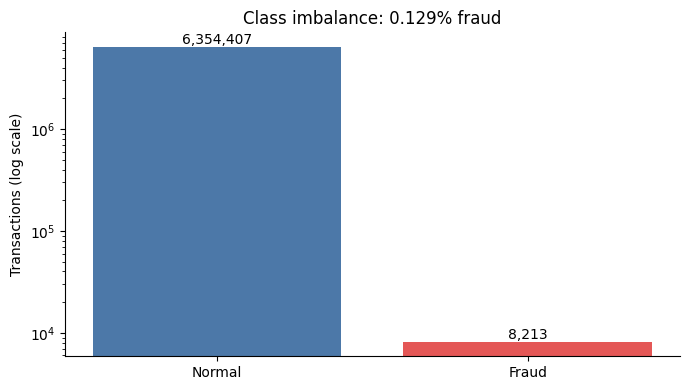

In [ ]:
counts = df["isFraud"].value_counts().sort_index()
frauds, normals = int(counts.get(1, 0)), int(counts.get(0, 0))
pct = 100 * frauds / len(df)
print(f"Normal: {normals:,}\nFraud:  {frauds:,}\nFraud rate: {pct:.3f}%  (about 1 in {len(df)//max(frauds,1):,})")
print(f"A model that always says 'not fraud' would be {100-pct:.2f}% accurate.")

fig, ax = plt.subplots()
ax.bar(["Normal", "Fraud"], [normals, frauds], color=["#4C78A8", "#E45756"])
ax.set_yscale("log"); ax.set_ylabel("Transactions (log scale)")
ax.set_title(f"Class imbalance: {pct:.3f}% fraud")
for i, v in enumerate([normals, frauds]): ax.text(i, v, f"{v:,}", ha="center", va="bottom")
fig.tight_layout(); fig.savefig("figures/01_class_imbalance.png", dpi=150); plt.show()

## 5. Which transaction types contain fraud?

,transactions,frauds,fraud_rate_%
type,,,
CASH_OUT,2237500,4116,0.18
TRANSFER,532909,4097,0.77
CASH_IN,1399284,0,0.00
DEBIT,41432,0,0.00
PAYMENT,2151495,0,0.00


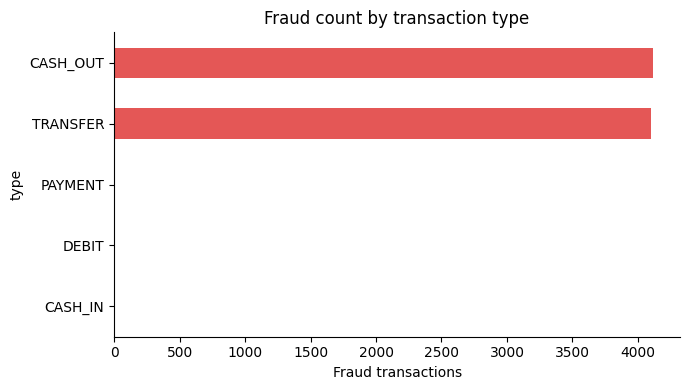

In [ ]:
by_type = df.groupby("type")["isFraud"].agg(transactions="count", frauds="sum")
by_type["fraud_rate_%"] = 100 * by_type["frauds"] / by_type["transactions"]
display(by_type.sort_values("frauds", ascending=False))

fig, ax = plt.subplots()
by_type["frauds"].sort_values().plot.barh(ax=ax, color="#E45756")
ax.set_xlabel("Fraud transactions"); ax.set_title("Fraud count by transaction type")
fig.tight_layout(); fig.savefig("figures/02_fraud_by_type.png", dpi=150); plt.show()

**What to note:** in standard PaySim, fraud only appears in `TRANSFER` and `CASH_OUT`. If that holds for your file, we can train on just those two types later, which shrinks the data a lot.

## 6. Amounts: fraud vs normal

               count         mean          std  min        25%        50%  \
isFraud                                                                     
0       6,354,407.00   178,197.04   596,236.98 0.01  13,368.40  74,684.72   
1           8,213.00 1,467,967.30 2,404,252.95 0.00 127,091.33 441,423.44   

                 75%           max  
isFraud                             
0         208,364.76 92,445,516.64  
1       1,517,771.48 10,000,000.00  


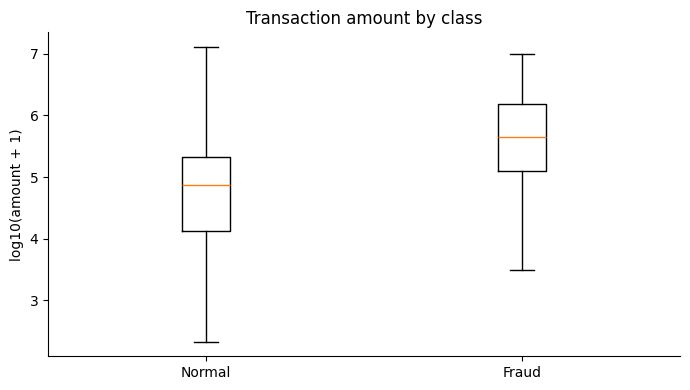

In [ ]:
print(df.groupby("isFraud")["amount"].describe())

fig, ax = plt.subplots()
data = [np.log10(df.loc[df.isFraud == 0, "amount"] + 1).sample(min(200000, normals), random_state=0),
        np.log10(df.loc[df.isFraud == 1, "amount"] + 1)]
ax.boxplot(data, showfliers=False)
ax.set_xticklabels(["Normal", "Fraud"])
ax.set_ylabel("log10(amount + 1)"); ax.set_title("Transaction amount by class")
fig.tight_layout(); fig.savefig("figures/03_amount_by_class.png", dpi=150); plt.show()

## 7. Time pattern
`step` is one hour of simulated time. Does the fraud rate change over the day?

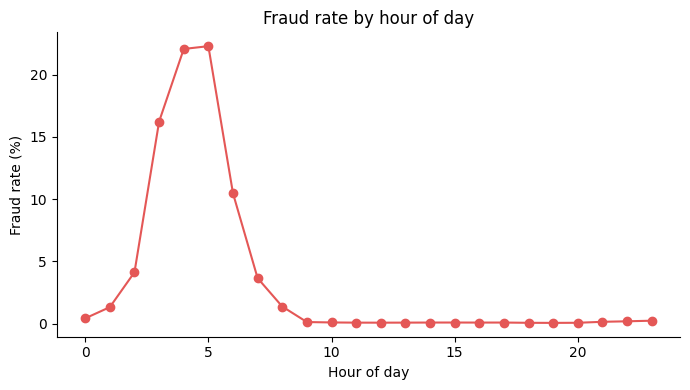

In [ ]:
df["hour_of_day"] = df["step"] % 24
h = df.groupby("hour_of_day")["isFraud"].agg(["count", "sum"])
h["fraud_rate_%"] = 100 * h["sum"] / h["count"]

fig, ax = plt.subplots()
ax.plot(h.index, h["fraud_rate_%"], marker="o", color="#E45756")
ax.set_xlabel("Hour of day"); ax.set_ylabel("Fraud rate (%)"); ax.set_title("Fraud rate by hour of day")
fig.tight_layout(); fig.savefig("figures/04_fraud_by_hour.png", dpi=150); plt.show()

## 8. Account structure (this decides steps 2 and 4)
- **Step 2** needs accounts that appear many times, to compute *transaction velocity* and *amount vs the account's average*.
- **Step 4** needs accounts that connect to each other, to build the *graph* for fraud rings.

In [ ]:
n_orig, n_dest = df["nameOrig"].nunique(), df["nameDest"].nunique()
print(f"Unique sender accounts:   {n_orig:,}   (transactions per sender: {len(df)/n_orig:.2f})")
print(f"Unique receiver accounts: {n_dest:,}   (transactions per receiver: {len(df)/n_dest:.2f})")

sender_counts = df["nameOrig"].value_counts()
print(f"\nSenders with more than 1 transaction: {(sender_counts > 1).sum():,}")
recv_counts = df["nameDest"].value_counts()
print(f"Receivers with more than 1 transaction: {(recv_counts > 1).sum():,}")
print(f"Accounts that are both a sender and a receiver: {len(set(df['nameOrig']) & set(df['nameDest'])):,}")

fraud_df = df[df.isFraud == 1]
print(f"\nFraud transactions: {len(fraud_df):,}")
print(f"Distinct receivers in fraud: {fraud_df['nameDest'].nunique():,}")
print("Top receivers in fraud transactions:")
print(fraud_df["nameDest"].value_counts().head(5))

Unique sender accounts:   6,353,307   (transactions per sender: 1.00)
Unique receiver accounts: 2,722,362   (transactions per receiver: 2.34)

Senders with more than 1 transaction: 9,298
Receivers with more than 1 transaction: 459,658
Accounts that are both a sender and a receiver: 1,769

Fraud transactions: 8,213
Distinct receivers in fraud: 8,169
Top receivers in fraud transactions:
nameDest
C1981613973    2
C410033330     2
C1366192319    2
C1655359478    2
C803116137     2
Name: count, dtype: int64


**Read this carefully and write down the result.** If senders almost never repeat (about 1 transaction each), then "velocity per sender account" has little to work with, and we would compute velocity on the **receiver** side or by time window instead. Your numbers above decide that. Do not guess; we design the features from these counts.

## 9. A leakage check (important for honest results)
PaySim has balance columns that can make the model look better than it really is. Fraud transactions often empty the sender's account. Let us measure it.

In [ ]:
df["orig_balance_error"] = df["oldbalanceOrg"] - df["amount"] - df["newbalanceOrig"]
df["dest_balance_error"] = df["newbalanceDest"] - df["oldbalanceDest"] - df["amount"]
df["orig_emptied"] = ((df["oldbalanceOrg"] > 0) & (df["newbalanceOrig"] == 0)).astype(int)

print("Share of transactions that empty the sender's account:")
print(df.groupby("isFraud")["orig_emptied"].mean().rename({0:"normal",1:"fraud"}).map("{:.1%}".format))
print("\nMean balance errors by class:")
print(df.groupby("isFraud")[["orig_balance_error", "dest_balance_error"]].mean())

Share of transactions that empty the sender's account:
isFraud
normal    23.8%
fraud     97.6%
Name: orig_emptied, dtype: object

Mean balance errors by class:
         orig_balance_error  dest_balance_error
isFraud                                        
0               -201,338.56          -54,692.23
1                -10,692.33         -732,509.30


**Why this matters:** if one balance column alone separates fraud almost perfectly, a model can score very high without learning anything useful. In your README, state this openly and report results with and without these columns. Recruiters trust honest reporting more than a perfect-looking score.

## 10. Summary for your notes

In [ ]:
summary = {
    "rows": len(df),
    "fraud_count": frauds,
    "fraud_rate_percent": round(pct, 4),
    "types_with_fraud": sorted(df.loc[df.isFraud == 1, "type"].unique().tolist()),
    "unique_senders": int(n_orig),
    "unique_receivers": int(n_dest),
    "senders_with_repeat_txns": int((sender_counts > 1).sum()),
    "hours_simulated": int(df["step"].max()),
}
import json
with open("figures/eda_summary.json", "w") as f: json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))

{
  "rows": 6362620,
  "fraud_count": 8213,
  "fraud_rate_percent": 0.1291,
  "types_with_fraud": [
    "CASH_OUT",
    "TRANSFER"
  ],
  "unique_senders": 6353307,
  "unique_receivers": 2722362,
  "senders_with_repeat_txns": 9298,
  "hours_simulated": 743
}


## Day 1-2 checklist
- [ ] Notebook ran with no errors
- [ ] You can explain in one sentence why accuracy is the wrong metric here
- [ ] `figures/` contains 4 charts and `eda_summary.json`
- [ ] You wrote down the account-structure numbers from section 8
- [ ] You can explain the leakage check in your own words

**Next (Day 3-4):** feature engineering and Feast. Send Claude the output of section 8 and section 9.

In [ ]:
   !zip -qr figures.zip figures
   from google.colab import files
   files.download("figures.zip")


zip error: Nothing to do! (try: zip -qr figures.zip . -i figures)


FileNotFoundError: Cannot find file: figures.zip